# Обучение модели
Задача регрессии: предсказать `price` за ночь по характеристикам объявления.
Данные читаются напрямую из S3 через boto3.

## Загрузка данных

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    make_scorer, mean_absolute_error, median_absolute_error,
    root_mean_squared_error, r2_score, mean_absolute_percentage_error,
)

from src.data import read_s3_csv

load_dotenv()
S3_BUCKET = os.environ["S3_BUCKET"]
S3_KEY = os.environ["S3_KEY"]

RANDOM_STATE = 42

In [2]:
df = read_s3_csv(S3_BUCKET, S3_KEY)
print(df.shape)
df.head()

(5724, 13)


,listing_id,snapshot_date,latitude,longitude,accommodates,bathrooms,bedrooms,beds,minimum_nights,neighbourhood_cleansed,property_type,room_type,price
0,1001248165793428398,2026-03-21,51.434110,-0.161020,2,1.0,1.0,1.0,1.0,Wandsworth,Entire serviced apartment,Entire home/apt,130.0
1,1001501494788436614,2026-03-21,51.514120,-0.176810,5,1.0,3.0,3.0,2.0,Westminster,Entire rental unit,Entire home/apt,232.0
2,1001555419418023705,2026-03-21,51.542042,0.121361,4,2.0,2.0,2.0,1.0,Barking and Dagenham,Entire condo,Entire home/apt,216.0
3,1001555573812356101,2026-03-21,51.540557,0.120994,2,1.0,1.0,1.0,1.0,Barking and Dagenham,Entire place,Entire home/apt,115.0
4,1001604905732387546,2026-03-21,51.377860,-0.086780,2,1.0,1.0,1.0,1.0,Croydon,Private room in home,Private room,86.0


## Изучение данных

In [3]:
df.isna().sum()

listing_id                 0
snapshot_date              0
latitude                   0
longitude                  0
accommodates               0
bathrooms                  6
bedrooms                   7
beds                      21
minimum_nights             1
neighbourhood_cleansed     0
property_type              0
room_type                  0
price                      0
dtype: int64

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5724 entries, 0 to 5723
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   listing_id              5724 non-null   int64  
 1   snapshot_date           5724 non-null   str    
 2   latitude                5724 non-null   float64
 3   longitude               5724 non-null   float64
 4   accommodates            5724 non-null   int64  
 5   bathrooms               5718 non-null   float64
 6   bedrooms                5717 non-null   float64
 7   beds                    5703 non-null   float64
 8   minimum_nights          5723 non-null   float64
 9   neighbourhood_cleansed  5724 non-null   str    
 10  property_type           5724 non-null   str    
 11  room_type               5724 non-null   str    
 12  price                   5724 non-null   float64
dtypes: float64(7), int64(2), str(4)
memory usage: 581.5 KB


In [5]:
df['snapshot_date'] = pd.to_datetime(df['snapshot_date'])

In [6]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
listing_id,5724.0,975578706257607808.0,42010.0,664416091484660992.0,1160765007141637120.0,1448640577035921408.0,1645727483680503296.0,574597724000003328.0
snapshot_date,5724,2026-03-21 00:00:00,2026-03-21 00:00:00,2026-03-21 00:00:00,2026-03-21 00:00:00,2026-03-21 00:00:00,2026-03-21 00:00:00,NaN
latitude,5724.0,51.507592,51.309717,51.484583,51.512263,51.535558,51.67128,0.050891
longitude,5724.0,-0.134593,-0.491268,-0.193513,-0.13736,-0.074339,0.22691,0.104187
accommodates,5724.0,3.578092,1.0,2.0,3.0,5.0,16.0,2.243911
bathrooms,5718.0,1.358255,0.0,1.0,1.0,1.5,12.0,0.746382
bedrooms,5717.0,1.560084,0.0,1.0,1.0,2.0,15.0,1.000403
beds,5703.0,1.98457,0.0,1.0,2.0,3.0,24.0,1.442128
minimum_nights,5723.0,2.183295,1.0,1.0,2.0,3.0,180.0,3.251723
price,5724.0,237.161324,17.93,97.0,168.375,273.88,23686.0,447.943062


In [7]:
df.describe(include='object').T

/var/folders/20/l216gx0d7476dgm0prfyp4k80000gn/T/ipykernel_3729/1760094569.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object').T


,count,unique,top,freq
neighbourhood_cleansed,5724,33,Westminster,791
property_type,5724,51,Entire rental unit,2527
room_type,5724,4,Entire home/apt,3933


In [8]:
df.duplicated().sum()

np.int64(0)

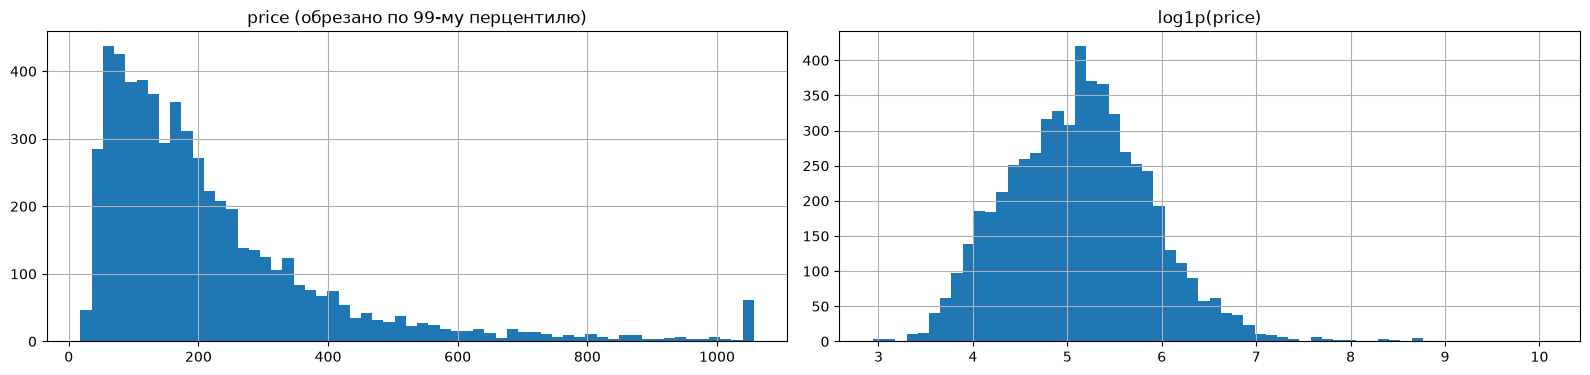

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))


df['price'].clip(upper=df['price'].quantile(0.99)).hist(bins=60, ax=axes[0])
axes[0].set_title("price (обрезано по 99-му перцентилю)")

np.log1p(df['price']).hist(bins=60, ax=axes[1])
axes[1].set_title("log1p(price)")


plt.suptitle("")
plt.tight_layout()
plt.show()

In [10]:
PRICE_MAX = 1000

n0 = len(df)
print("Объявлений дороже £1000:", (df["price"] > PRICE_MAX).sum())
df = df[(df["price"] > 0) & (df["price"] <= PRICE_MAX)].reset_index(drop=True)
print(f"Было {n0}, осталось {len(df)} ({len(df) / n0:.1%})")

Объявлений дороже £1000: 70
Было 5724, осталось 5654 (98.8%)


## Разделение на train / test

In [11]:
NUM_COLS = ["latitude", "longitude", "accommodates", "bathrooms", "bedrooms", "beds", "minimum_nights"]
CAT_COLS = ["neighbourhood_cleansed", "property_type", "room_type"]

In [12]:
X = df[NUM_COLS + CAT_COLS]
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)


print("train:", X_train.shape, " test:", X_test.shape)
print(f"Медиана цены: train £{y_train.median():.0f}, test £{y_test.median():.0f}")

train: (4523, 10)  test: (1131, 10)
Медиана цены: train £166, test £166


## Преобразование признаков

In [13]:
MIN_COUNT = 20
RARE_GROUP_COLS = ["property_type"]

medians = X_train[NUM_COLS].median()

frequent = {}
for col in RARE_GROUP_COLS:
    counts = X_train[col].value_counts()
    frequent[col] = counts[counts >= MIN_COUNT].index
    print(f"{col}: оставляем {len(frequent[col])} из {counts.size}, "
          f"покрытие {counts[frequent[col]].sum() / counts.sum():.1%}")


def prepare(X):
    X = X[NUM_COLS + CAT_COLS].copy()
    X[NUM_COLS] = X[NUM_COLS].fillna(medians)
    for col in RARE_GROUP_COLS:
        X[col] = X[col].where(X[col].isin(frequent[col]), "Other")
    return pd.get_dummies(X, columns=CAT_COLS, dtype=float)


X_train_prep = prepare(X_train)
X_test_prep = prepare(X_test).reindex(columns=X_train_prep.columns, fill_value=0.0)

property_type: оставляем 11 из 50, покрытие 96.4%


In [14]:
print("train:", X_train_prep.shape, " test:", X_test_prep.shape)
X_train_prep.head()

train: (4523, 56)  test: (1131, 56)


,latitude,longitude,accommodates,bathrooms,bedrooms,beds,minimum_nights,neighbourhood_cleansed_Barking and Dagenham,neighbourhood_cleansed_Barnet,neighbourhood_cleansed_Bexley,...,property_type_Private room in bed and breakfast,property_type_Private room in condo,property_type_Private room in home,property_type_Private room in rental unit,property_type_Private room in townhouse,property_type_Room in hotel,room_type_Entire home/apt,room_type_Hotel room,room_type_Private room,room_type_Shared room
670,51.560390,-0.280800,4,1.0,1.0,2.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3484,51.537900,-0.002330,5,2.0,2.0,2.0,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2767,51.490033,-0.117796,2,1.0,1.0,2.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1620,51.575066,-0.262169,2,1.0,1.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3606,51.509658,-0.193159,3,1.0,1.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train_prep)
X_train_scaled = scaler.transform(X_train_prep)
X_test_scaled = scaler.transform(X_test_prep)

## Обучение моделей

In [16]:
y_train_log = np.log1p(y_train)


def mae_pounds(y_true_log, y_pred_log):
    return mean_absolute_error(np.expm1(y_true_log), np.expm1(y_pred_log))


def rmse_pounds(y_true_log, y_pred_log):
    return root_mean_squared_error(np.expm1(y_true_log), np.expm1(y_pred_log))


def r2_pounds(y_true_log, y_pred_log):
    return r2_score(np.expm1(y_true_log), np.expm1(y_pred_log))


SCORING = {
    "mae": make_scorer(mae_pounds, greater_is_better=False),
    "rmse": make_scorer(rmse_pounds, greater_is_better=False),
    "r2": make_scorer(r2_pounds),
}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [17]:
res = cross_validate(DummyRegressor(strategy="median"), X_train_prep, y_train_log,
                     cv=cv, scoring=SCORING, return_train_score=True)

rows = [{
    "model": "Baseline (медиана)",
    "cv_MAE": -res["test_mae"].mean(),
    "cv_MAE_std": res["test_mae"].std(),
    "cv_RMSE": -res["test_rmse"].mean(),
    "cv_R2": res["test_r2"].mean(),
    "train_MAE": -res["train_mae"].mean(),
}]
pd.DataFrame(rows).set_index("model").round(3)

,cv_MAE,cv_MAE_std,cv_RMSE,cv_R2,train_MAE
model,,,,,
Baseline (медиана),109.597,3.177,163.688,-0.071,109.587


In [18]:
candidates = {
    "Ridge": (
        Ridge(),
        {"alpha": [10, 100, 300, 1000]},
        X_train_scaled,
    ),
    "RandomForest": (
        RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
        {
            "max_depth": [None, 20],
            "min_samples_leaf": [1, 3, 5],
            "max_features": [1.0, 0.5],
        },
        X_train_prep,
    ),
    "HistGradientBoosting": (
        HistGradientBoostingRegressor(max_iter=500, random_state=RANDOM_STATE),
        {
            "learning_rate": [0.01, 0.03, 0.05],
            "max_leaf_nodes": [7, 15, 31],
            "min_samples_leaf": [30, 60, 100],
            "l2_regularization": [1.0, 5.0],
        },
        X_train_prep,
    ),
}

searches = {}
for name, (model, grid, X_fit) in candidates.items():
    search = GridSearchCV(model, grid, cv=cv, scoring=SCORING, refit="mae",
                          return_train_score=True, n_jobs=-1)
    search.fit(X_fit, y_train_log)
    searches[name] = search

    r, i = search.cv_results_, search.best_index_
    rows.append({
        "model": name,
        "cv_MAE": -r["mean_test_mae"][i],
        "cv_MAE_std": r["std_test_mae"][i],
        "cv_RMSE": -r["mean_test_rmse"][i],
        "cv_R2": r["mean_test_r2"][i],
        "train_MAE": -r["mean_train_mae"][i],
    })
    print(f"{name}: cv_MAE = £{-search.best_score_:.2f}, лучшие параметры: {search.best_params_}")

results = pd.DataFrame(rows).set_index("model").sort_values("cv_MAE")
results.round(3)

Ridge: cv_MAE = £66.74, лучшие параметры: {'alpha': 300}
RandomForest: cv_MAE = £61.53, лучшие параметры: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 3}
HistGradientBoosting: cv_MAE = £60.36, лучшие параметры: {'l2_regularization': 5.0, 'learning_rate': 0.03, 'max_leaf_nodes': 31, 'min_samples_leaf': 100}


,cv_MAE,cv_MAE_std,cv_RMSE,cv_R2,train_MAE
model,,,,,
HistGradientBoosting,60.358,1.238,99.510,0.604,49.869
RandomForest,61.527,1.161,101.227,0.590,41.488
Ridge,66.743,2.682,113.438,0.483,65.476
Baseline (медиана),109.597,3.177,163.688,-0.071,109.587


In [19]:
best_name = results.drop(index="Baseline (медиана)").index[0]
best_search = searches[best_name]
print("Лучшая модель:", best_name, best_search.best_params_)

Лучшая модель: HistGradientBoosting {'l2_regularization': 5.0, 'learning_rate': 0.03, 'max_leaf_nodes': 31, 'min_samples_leaf': 100}


In [20]:
best_model = best_search.best_estimator_
X_test_best = X_test_scaled if best_name == "Ridge" else X_test_prep
print(best_name, best_search.best_params_)


def regression_report(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MedianAE": median_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


pred_test = np.expm1(best_model.predict(X_test_best))  # обратно в фунты
pred_baseline = np.full(len(y_test), y_train.median())

assert np.isfinite(pred_test).all(), "в предсказаниях есть NaN/inf"
assert (pred_test > 0).all(), "модель предсказала неположительную цену"

test_report = pd.DataFrame({
    "Baseline (медиана)": regression_report(y_test, pred_baseline),
    best_name: regression_report(y_test, pred_test),
}).T
test_report.round(3)

HistGradientBoosting {'l2_regularization': 5.0, 'learning_rate': 0.03, 'max_leaf_nodes': 31, 'min_samples_leaf': 100}


,MAE,MedianAE,RMSE,R2
Baseline (медиана),114.440,79.000,173.019,-0.083
HistGradientBoosting,61.691,35.424,98.160,0.651
